# Can the model learn independent daily returns?

Train on four Gaussian return series with known volatility and correlation between stocks,
but no dependence across days. This checks whether the model can learn a simple target.
Use the `.venv` kernel and run from the top.


In [ ]:
from pathlib import Path
import json
import os
import sys
from time import perf_counter

os.environ["JAX_PLATFORMS"] = "cpu"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "experiments/4stocks/sde_gan.py").is_file())
experiment_dir = root / "experiments/4stocks"
if str(experiment_dir) not in sys.path:
    sys.path.insert(0, str(experiment_dir))
from sde_gan import SDEGAN, SDEGANConfig

MODE = "train"  # "inspect" reloads saved models without fitting.
GENERATOR_OUTPUT = "increments"  # First test the old model; then repeat with "increments".
TRAINING_SEEDS = [0]  # Repeat with [0, 1, 2] after the first comparison.
GENERATOR_STEPS = 2000
N_TRAIN, N_VALIDATION = 1679, 709
N_PATHS = 1000
REFERENCE_REPEATS = 200
DATA_SEED, SAMPLE_SEED = 2026, 100
SERIES = ["Series 1", "Series 2", "Series 3", "Series 4"]
TARGET_MEAN = np.zeros(4)
TARGET_STD = np.array([0.018, 0.036, 0.018, 0.019])  # Daily log-return standard deviations.
TARGET_CORR = 0.5 * np.eye(4) + 0.5 * np.ones((4, 4))

if MODE not in {"train", "inspect"}:
    raise ValueError("MODE must be train or inspect")
if "generator_output" not in SDEGANConfig.__dataclass_fields__:
    raise RuntimeError("Restart the kernel to load the updated model code")
config = SDEGANConfig(generator_output=GENERATOR_OUTPUT,
                      generator_steps=GENERATOR_STEPS,
                      temporal_penalty_weight=0, signature_loss_weight=0,
                      retain_validation_checkpoints=True)
runs_dir = experiment_dir / "results/synthetic_iid" / GENERATOR_OUTPUT
print(f"Python: {sys.executable}")
print(f"Output: {GENERATOR_OUTPUT}; {GENERATOR_STEPS} generator updates per seed")
print(f"Results: {runs_dir}")


Python: /Users/pasha/Desktop/master/master_thesis/sandbox/.venv/bin/python
Output: returns; 2000 generator updates per seed
Results: /Users/pasha/Desktop/master/master_thesis/sandbox/4stocks_experiment/results/synthetic_iid/returns


## Make the known target

Draw separate training and validation windows. Each day gets fresh noise; stocks share
correlation 0.5 on the same day. Scale using training data only, as in the stock pipeline.
All ACF calculations below use pairs inside windows, never across their boundaries.


In [2]:
chol = np.linalg.cholesky(TARGET_CORR)

def draw_returns(rng: np.random.Generator, n_paths: int) -> np.ndarray:
    """Draw independent days with the specified joint Gaussian log returns."""
    return TARGET_MEAN + (rng.normal(size=(n_paths, 20, 4)) @ chol.T) * TARGET_STD

train_log = draw_returns(np.random.default_rng(DATA_SEED), N_TRAIN)
validation_log = draw_returns(np.random.default_rng(DATA_SEED + 1), N_VALIDATION)
reference_log = draw_returns(np.random.default_rng(DATA_SEED + 2), N_PATHS)
scaler_mean = train_log.reshape(-1, 4).mean(axis=0)
scaler_std = train_log.reshape(-1, 4).std(axis=0, ddof=1)
train_windows = ((train_log - scaler_mean) / scaler_std).astype(np.float32)
validation_windows = ((validation_log - scaler_mean) / scaler_std).astype(np.float32)
setup = {"data_seed": DATA_SEED, "n_train": N_TRAIN, "n_validation": N_VALIDATION,
         "target_mean": TARGET_MEAN.tolist(), "target_std": TARGET_STD.tolist(),
         "target_corr": TARGET_CORR.tolist(), "scaler_mean": scaler_mean.tolist(),
         "scaler_std": scaler_std.tolist(), "units": "daily log returns"}
np.testing.assert_allclose(train_windows.reshape(-1, 4).mean(0), 0, atol=1e-6)
np.testing.assert_allclose(train_windows.reshape(-1, 4).std(0, ddof=1), 1, atol=1e-5)
display(pd.DataFrame({"target mean (%)": TARGET_MEAN * 100,
                      "target daily std (%)": TARGET_STD * 100}, index=SERIES))
print(f"Training: {train_windows.shape}; validation: {validation_windows.shape}")


,target mean (%),target daily std (%)
Series 1,0.0,1.8
Series 2,0.0,3.6
Series 3,0.0,1.8
Series 4,0.0,1.9


Training: (1679, 20, 4); validation: (709, 20, 4)


## Train or reload

Use the normal 2,000-update budget with no ACF or signature penalty. Save every validation
checkpoint. The selected model uses the existing lowest-validation-MMD rule; the final
checkpoint shows what training reached. Changing the output option uses a separate folder.


In [3]:
models, histories, checkpoint_rows = {}, {}, []
for seed in TRAINING_SEEDS:
    run_dir = runs_dir / f"seed_{seed}"
    if MODE == "train":
        model = SDEGAN(config)
        started = perf_counter()
        print(f"Training seed {seed} ...", flush=True)
        model.fit(train_windows, validation_windows, seed=seed)
        model.save(run_dir)
        (run_dir / "synthetic_setup.json").write_text(json.dumps(setup, indent=2) + "\n")
        print(f"Finished seed {seed} in {(perf_counter() - started) / 60:.1f} minutes")
    if json.loads((run_dir / "synthetic_setup.json").read_text()) != setup:
        raise ValueError("Saved data settings differ; use the original setup to inspect this run")
    selected = SDEGAN.load(run_dir)
    if selected.config.generator_output != GENERATOR_OUTPUT:
        raise ValueError("Checkpoint uses a different generator output")
    final_step = selected.config.generator_steps
    final = SDEGAN.load(run_dir / "checkpoints" / f"step_{final_step:04d}")
    histories[seed] = pd.DataFrame(selected.history)
    for name, model in [("selected", selected), ("final", final)]:
        label = f"seed {seed}: {name}"
        models[label] = model
        checkpoint_rows.append({"model": label, "step": model.run_metadata["selected_step"],
                                "validation MMD²": model.run_metadata["validation_score"]})
display(pd.DataFrame(checkpoint_rows).set_index("model"))


Training seed 0 ...
Finished seed 0 in 13.2 minutes


,step,validation MMD²
model,,
seed 0: selected,1200,0.012772
seed 0: final,2000,0.017233


## Follow learning

Plot validation MMD, ACF error, and volatility error over training. A lower MMD alone does
not establish that the model learned independent days or the correct volatility.


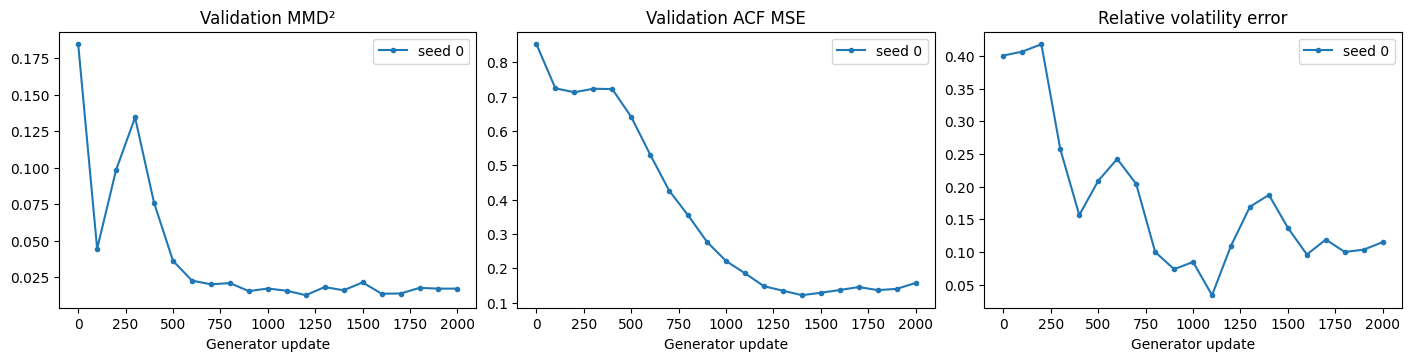

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), constrained_layout=True)
for seed, history in histories.items():
    scores = history.dropna(subset=["validation_mmd2"])
    for ax, metric in zip(axes, ["validation_mmd2", "validation_temporal_error",
                                 "validation_volatility_error"]):
        ax.plot(scores.step, scores[metric], marker=".", label=f"seed {seed}")
for ax, title in zip(axes, ["Validation MMD²", "Validation ACF MSE", "Relative volatility error"]):
    ax.set(title=title, xlabel="Generator update")
    ax.legend()
fig.savefig(runs_dir / "learning.png", dpi=150)
plt.show()
plt.close(fig)


## Measure generated returns

Restore log-return units and compare means, volatility, correlations between stocks, and
ACF at lags 1–5. Signed and absolute-return ACF should both be zero for this target.
The limits below are practical screening choices, not a statistical proof of a match.


In [5]:
def acf(values: np.ndarray) -> np.ndarray:
    """Pool matching lag pairs within windows, separately for each series."""
    result = []
    for lag in range(1, 6):
        a = values[:, :-lag].reshape(-1, 4)
        b = values[:, lag:].reshape(-1, 4)
        a, b = a - a.mean(0), b - b.mean(0)
        denominator = np.sqrt((a * a).mean(0) * (b * b).mean(0))
        result.append(np.divide((a * b).mean(0), denominator,
                                out=np.full(4, np.nan), where=denominator > 0))
    return np.array(result)


def metrics(values: np.ndarray) -> dict:
    """Compare a generated ensemble with known population targets."""
    flat = values.reshape(-1, 4)
    corr = np.corrcoef(flat.T)
    off_diagonal = ~np.eye(4, dtype=bool)
    return {"mean error / target std": np.max(np.abs(flat.mean(0) - TARGET_MEAN) / TARGET_STD),
            "max relative std error": np.max(np.abs(flat.std(0, ddof=1) / TARGET_STD - 1)),
            "max absolute signed ACF": np.max(np.abs(acf(values))),
            "max absolute abs-return ACF": np.max(np.abs(acf(np.abs(values)))),
            "cross-stock correlation RMSE": np.sqrt(np.mean((corr - TARGET_CORR)[off_diagonal] ** 2))}


generated = {label: model.sample(N_PATHS, SAMPLE_SEED).astype(np.float64) * scaler_std + scaler_mean
             for label, model in models.items()}
assert all(x.shape == (N_PATHS, 20, 4) and np.isfinite(x).all() for x in generated.values())
datasets = {"training": train_log, "validation": validation_log,
            "fresh target": reference_log, **generated}
summary = pd.DataFrame({name: metrics(values) for name, values in datasets.items()}).T
limits = pd.Series({"mean error / target std": 0.05, "max relative std error": 0.10,
                    "max absolute signed ACF": 0.05, "max absolute abs-return ACF": 0.05,
                    "cross-stock correlation RMSE": 0.05})
checks = summary.le(limits) & np.isfinite(summary)
summary.to_csv(runs_dir / "metrics.csv")
checks.to_csv(runs_dir / "screening_checks.csv")
limits.to_csv(runs_dir / "screening_limits.csv", header=["limit"])
display(summary.round(4))
print("Screening limits:")
display(limits)
print("Within each limit:")
display(checks)


,mean error / target std,max relative std error,max absolute signed ACF,max absolute abs-return ACF,cross-stock correlation RMSE
training,0.0069,0.0076,0.0154,0.0167,0.0026
validation,0.0230,0.0105,0.0196,0.0162,0.0091
fresh target,0.0122,0.0055,0.0194,0.0219,0.0044
seed 0: selected,0.1464,0.1290,0.7062,0.5189,0.3065
seed 0: final,0.1458,0.1558,0.7108,0.4928,0.2999


Screening limits:


mean error / target std         0.05
max relative std error          0.10
max absolute signed ACF         0.05
max absolute abs-return ACF     0.05
cross-stock correlation RMSE    0.05
dtype: float64

Within each limit:


,mean error / target std,max relative std error,max absolute signed ACF,max absolute abs-return ACF,cross-stock correlation RMSE
training,True,True,True,True,True
validation,True,True,True,True,True
fresh target,True,True,True,True,True
seed 0: selected,False,False,False,False,False
seed 0: final,False,False,False,False,False


## Compare volatility and distributions

Check that reducing ACF has not shrunk the returns. Bars show daily log-return volatility;
CDF curves show how often returns fall below each value. Generated curves should follow
the fresh target sample.


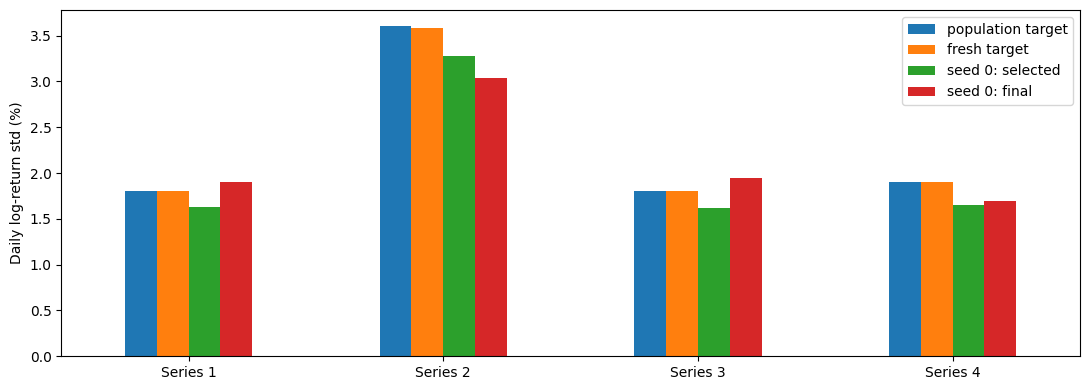

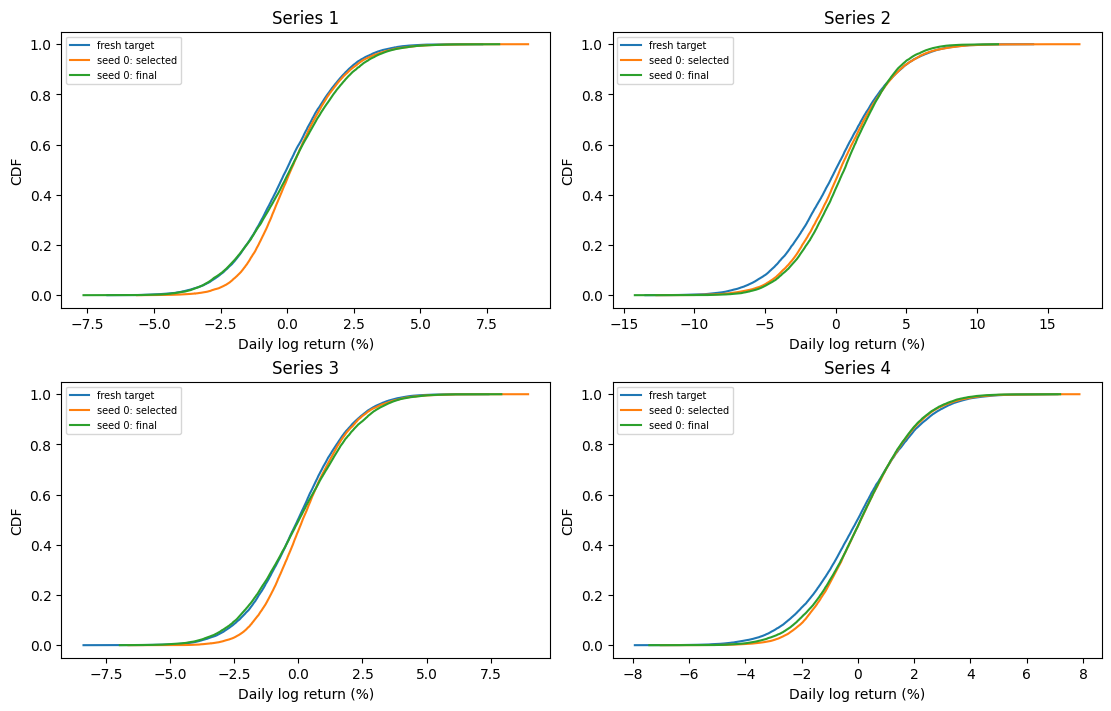

In [6]:
plot_data = {"fresh target": reference_log, **generated}
volatility = pd.DataFrame({name: values.reshape(-1, 4).std(0, ddof=1) * 100
                           for name, values in plot_data.items()}, index=SERIES)
volatility.insert(0, "population target", TARGET_STD * 100)
volatility.to_csv(runs_dir / "daily_volatility_percent.csv")
ax = volatility.plot.bar(figsize=(11, 4), rot=0, ylabel="Daily log-return std (%)")
ax.figure.tight_layout()
ax.figure.savefig(runs_dir / "volatility.png", dpi=150)
plt.show()
plt.close(ax.figure)
fig, axes = plt.subplots(2, 2, figsize=(11, 7), constrained_layout=True)
for stock, ax in enumerate(axes.flat):
    for name, values in plot_data.items():
        ordered = np.sort(values[:, :, stock].ravel()) * 100
        ax.plot(ordered, np.arange(1, len(ordered) + 1) / len(ordered), label=name)
    ax.set(title=SERIES[stock], xlabel="Daily log return (%)", ylabel="CDF")
    ax.legend(fontsize=7)
fig.savefig(runs_dir / "return_cdf.png", dpi=150)
plt.show()
plt.close(fig)


## Check dependence across days

Both rows should stay near zero. Bands show the central 95% range from repeated independent
target samples of the same size as the generated ensemble. They show sampling variation;
checking many points can put some outside the bands even for a correct model.


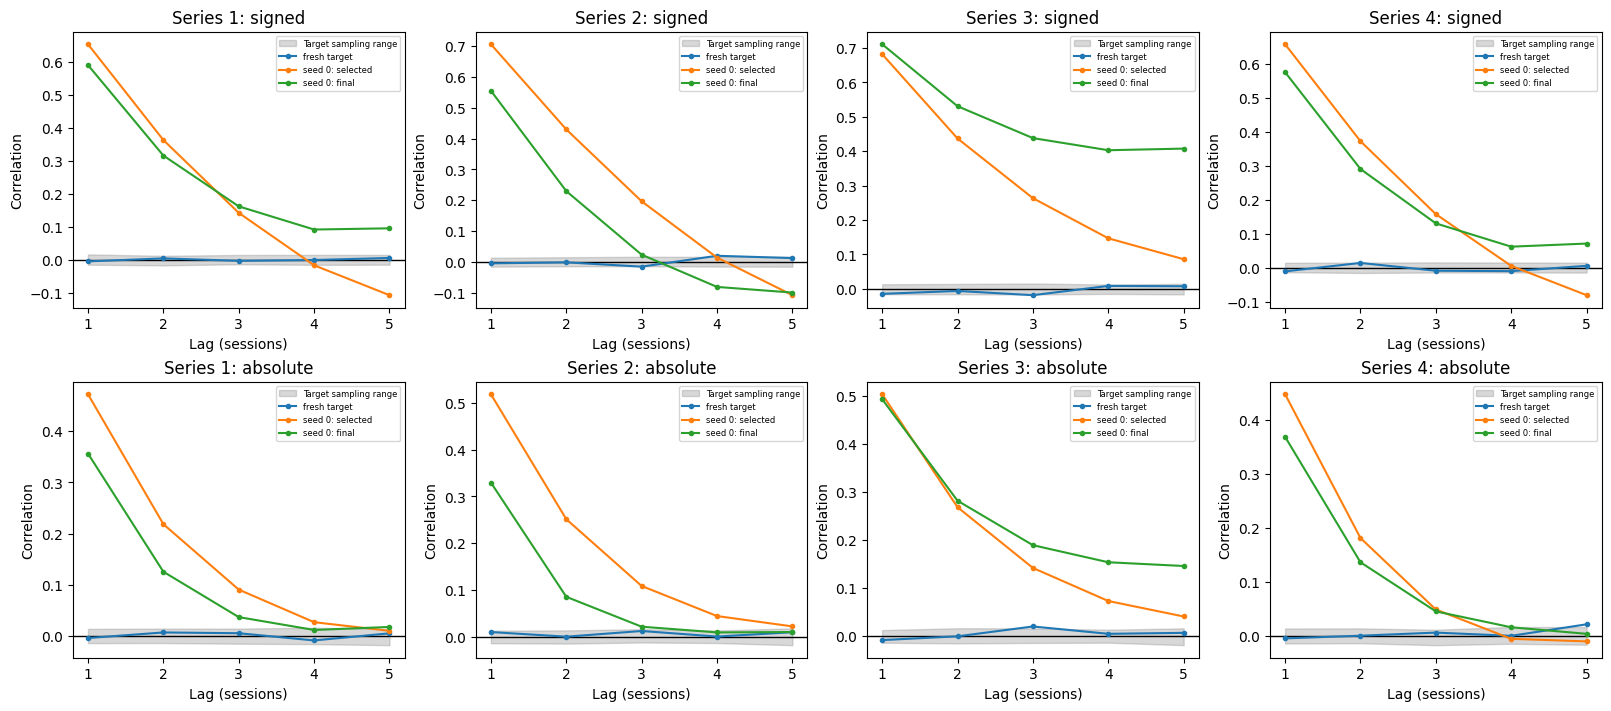

In [7]:
rng = np.random.default_rng(DATA_SEED + 3)
reference_acfs = []
for _ in range(REFERENCE_REPEATS):
    sample = draw_returns(rng, N_PATHS)
    reference_acfs.append(np.stack([acf(sample), acf(np.abs(sample))]))
bands = np.quantile(reference_acfs, [0.025, 0.975], axis=0)
np.savez(runs_dir / "acf_reference_bands.npz", bands=bands, n_paths=N_PATHS,
         repeats=REFERENCE_REPEATS, seed=DATA_SEED + 3)
fig, axes = plt.subplots(2, 4, figsize=(16, 7), constrained_layout=True)
acf_rows = []
for row, transform in enumerate([lambda x: x, np.abs]):
    for stock in range(4):
        ax = axes[row, stock]
        ax.fill_between(range(1, 6), bands[0, row, :, stock], bands[1, row, :, stock],
                        color="grey", alpha=0.3, label="Target sampling range")
        ax.axhline(0, color="black", linewidth=1)
        for name, values in plot_data.items():
            coefficients = acf(transform(values))[:, stock]
            ax.plot(range(1, 6), coefficients, marker=".", label=name)
            for lag, value in enumerate(coefficients, 1):
                acf_rows.append({"dataset": name, "kind": ["signed", "absolute"][row],
                                 "series": SERIES[stock], "lag": lag, "acf": value})
        ax.set(title=f"{SERIES[stock]}: {['signed', 'absolute'][row]}",
               xlabel="Lag (sessions)", ylabel="Correlation", xticks=range(1, 6))
        ax.legend(fontsize=6)
pd.DataFrame(acf_rows).to_csv(runs_dir / "acf.csv", index=False)
fig.savefig(runs_dir / "acf.png", dpi=150)
plt.show()
plt.close(fig)


## Read the result

The screen checks all five properties together. Success on this simple target supports
moving on to market data; it does not establish that real market paths are reproduced.


In [8]:
for label in generated:
    failed = checks.columns[~checks.loc[label]].tolist()
    if failed:
        print(f"{label}: outside the screening limits for {', '.join(failed)}.")
    else:
        print(f"{label}: within all five screening limits for this synthetic target.")
print("Repeat with generator_output='increments' using the same seeds and budget to compare architectures.")
print(f"Saved models, tables, and figures: {runs_dir}")


seed 0: selected: outside the screening limits for mean error / target std, max relative std error, max absolute signed ACF, max absolute abs-return ACF, cross-stock correlation RMSE.
seed 0: final: outside the screening limits for mean error / target std, max relative std error, max absolute signed ACF, max absolute abs-return ACF, cross-stock correlation RMSE.
Repeat with generator_output='increments' using the same seeds and budget to compare architectures.
Saved models, tables, and figures: /Users/pasha/Desktop/master/master_thesis/sandbox/4stocks_experiment/results/synthetic_iid/returns
